# 🔬 TensorFlow Experiments — Nitrate Nowcasting
> Estación Yeguas · 4 arquitecturas · Walk-Forward Validation · Integrated Gradients

**Arquitecturas comparadas**
| ID | Modelo |
|---|---|
| A | MLP Wide & Deep |
| B | GRU |
| C | 1D-CNN + LSTM |
| D | Transformer (Atención Temporal) |

## 0 · Setup & Cargar datos

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers, regularizers
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import mlflow
import mlflow.tensorflow
import optuna
import joblib, json

optuna.logging.set_verbosity(optuna.logging.WARNING)  # silencia logs de Optuna

print(f'TensorFlow {tf.__version__}')
print(f'MLflow     {mlflow.__version__}')
print(f'Optuna     {optuna.__version__}')
tf.random.set_seed(42)
np.random.seed(42)

# ── Paleta de colores por modelo ──────────────────────────────────────────────
COLORS = {'A_WideDeep': '#2196F3', 'B_GRU': '#4CAF50', 'C_CNN_LSTM': '#FF9800', 'D_Transformer': '#9C27B0'}
MODEL_NAMES = {'A_WideDeep': 'Wide & Deep', 'B_GRU': 'GRU', 'C_CNN_LSTM': '1D-CNN+LSTM', 'D_Transformer': 'Transformer'}


TensorFlow 2.20.0
MLflow     3.10.0
Optuna     4.7.0


In [2]:
# ── Configuración MLflow ──────────────────────────────────────────────────────
MLFLOW_EXPERIMENT = "nitrate_nowcasting"
MLFLOW_TRACKING_URI = "http://mlflow.example.com:5000"          # carpeta local; cambia a http://... para servidor remoto

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)

exp = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT)
print(f'Experimento : {MLFLOW_EXPERIMENT}')
print(f'Tracking URI: {mlflow.get_tracking_uri()}')
print(f'Experiment ID: {exp.experiment_id}')
print()
print('Para visualizar los resultados, ejecuta en la terminal:')
print('  mlflow ui --port 5000')
print('  → http://mlflow.example.com:5000')

Experimento : nitrate_nowcasting
Tracking URI: http://mlflow.example.com:5000
Experiment ID: 3

Para visualizar los resultados, ejecuta en la terminal:
  mlflow ui --port 5000
  → http://mlflow.example.com:5000


In [3]:
# ── Carga y limpieza ──────────────────────────────────────────────────────────
df = pd.read_csv('data/processed/YEGUAS_data.csv')
df['_time'] = pd.to_datetime(df['_time'])
df = df.set_index('_time').sort_index()

# Eliminar columnas NITRATE excepto el target Y
cols_to_drop = [c for c in df.columns if 'NITRATE' in c and c != 'NITRATE_nitrate_no3_mg_l']
df = df.drop(columns=cols_to_drop)
df = df.dropna(subset=['NITRATE_nitrate_no3_mg_l'])
df = df.interpolate(method='linear').dropna()

# ── Eliminar variables colineales con conductivity ────────────────────────────
# TDS ≈ conductivity × factor; salinity ≈ f(conductivity) → información redundante
_colineal = [c for c in ['C4E_tds', 'C4E_salinity'] if c in df.columns]
if _colineal:
    df = df.drop(columns=_colineal)
    print(f'Columnas colineales eliminadas: {_colineal}')

# ── Ingeniería de variables: ciclo día/noche ──────────────────────────────────
_hour = df.index.hour
df['hour_sin'] = np.sin(2 * np.pi * _hour / 24)
df['hour_cos'] = np.cos(2 * np.pi * _hour / 24)

print(f'Filas: {len(df)}  |  Features: {df.shape[1]-1}  |  Target: NITRATE_nitrate_no3_mg_l')
print(f'Rango: {df.index[0]}  →  {df.index[-1]}')
df.head(3)


Columnas colineales eliminadas: ['C4E_tds', 'C4E_salinity']
Filas: 3119  |  Features: 12  |  Target: NITRATE_nitrate_no3_mg_l
Rango: 2025-12-10 13:54:09  →  2026-02-16 23:31:18


,C4E_conductivity,C4E_temperature,NITRATE_nitrate_no3_mg_l,NTU_fnu,NTU_mgL,NTU_ntu,NTU_temperature,OPTOD_mgL,OPTOD_ppm,OPTOD_saturation,OPTOD_temperature,hour_sin,hour_cos
_time,,,,,,,,,,,,,
2025-12-10 13:54:09,2254.0,17.6,53.4,6.46,13.3,6.46,17.7,7.89,7.89,80.6,16.6,-0.258819,-0.965926
2025-12-10 14:25:36,2262.0,17.5,54.5,9.58,17.8,9.58,17.7,7.52,7.52,78.7,17.7,-0.500000,-0.866025
2025-12-10 14:57:04,2286.0,17.2,54.1,15.60,27.1,15.60,17.4,7.51,7.51,78.2,17.5,-0.500000,-0.866025


## 1 · Preprocesado

In [4]:
TARGET = 'NITRATE_nitrate_no3_mg_l'
FEATURE_COLS = [c for c in df.columns if c != TARGET]

# ── Hiperparámetros globales ──────────────────────────────────────────────────
WINDOW = 24         # pasos de 30 min = 12 h de historia
LAG_STEPS = [1, 2, 4]  # lags para Wide & Deep

# ── Separar X e Y ─────────────────────────────────────────────────────────────
y_raw = df[TARGET].values
X_raw = df[FEATURE_COLS].values

# ── Escalado ──────────────────────────────────────────────────────────────────
X_scaler = StandardScaler()
X_scaled = X_scaler.fit_transform(X_raw)

y_scaler = MinMaxScaler()
y_scaled = y_scaler.fit_transform(y_raw.reshape(-1, 1)).flatten()

print(f'X escalado: {X_scaled.shape}  |  y escalado: {y_scaled.shape}')
print(f'Features  : {FEATURE_COLS}')


X escalado: (3119, 12)  |  y escalado: (3119,)
Features  : ['C4E_conductivity', 'C4E_temperature', 'NTU_fnu', 'NTU_mgL', 'NTU_ntu', 'NTU_temperature', 'OPTOD_mgL', 'OPTOD_ppm', 'OPTOD_saturation', 'OPTOD_temperature', 'hour_sin', 'hour_cos']


In [5]:
# ── Función para crear ventanas temporales (modelos B/C/D) ────────────────────
def make_sequences(X, y, window):
    """Genera arrays 3D (n_samples, window, n_features) para modelos recurrentes."""
    Xs, ys = [], []
    for i in range(window - 1, len(X)):
        Xs.append(X[i - window + 1 : i + 1])
        ys.append(y[i])
    return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.float32)

# ── Función para crear lag features (modelo A Wide & Deep) ───────────────────
def make_lag_features(X, y, lags):
    """Añade columnas de lag. Retorna arrays 2D para MLP."""
    max_lag = max(lags)
    lag_arrays = [X[max_lag:]]
    for lag in lags:
        lag_arrays.append(X[max_lag - lag : len(X) - lag])
    X_with_lags = np.concatenate(lag_arrays, axis=1)
    y_aligned = y[max_lag:]
    return X_with_lags.astype(np.float32), y_aligned.astype(np.float32)

X_seq, y_seq = make_sequences(X_scaled, y_scaled, WINDOW)
X_lag, y_lag = make_lag_features(X_scaled, y_scaled, LAG_STEPS)

print(f'Secuencias  (B/C/D): {X_seq.shape}')
print(f'Lag features  (A):   {X_lag.shape}')

Secuencias  (B/C/D): (3096, 24, 12)
Lag features  (A):   (3115, 48)


## 2 · Walk-Forward Validation — Definición de Folds

In [6]:
def make_folds(n_samples, n_folds=5, min_train_ratio=0.6):
    """Genera índices para walk-forward expanding-window."""
    min_train = int(n_samples * min_train_ratio)
    remaining = n_samples - min_train
    fold_size = remaining // n_folds
    folds = []
    for k in range(n_folds):
        train_end = min_train + k * fold_size
        test_end  = train_end + fold_size
        if k == n_folds - 1:
            test_end = n_samples  # último fold usa todo lo que queda
        folds.append((slice(0, train_end), slice(train_end, test_end)))
    return folds

N_FOLDS = 5
folds_seq = make_folds(len(X_seq), N_FOLDS)
folds_lag = make_folds(len(X_lag), N_FOLDS)

print('Folds walk-forward (secuencias):')
for i, (tr, te) in enumerate(folds_seq):
    print(f'  Fold {i+1}: train[{tr.start}:{tr.stop}]  test[{te.start}:{te.stop}]')

Folds walk-forward (secuencias):
  Fold 1: train[0:1857]  test[1857:2104]
  Fold 2: train[0:2104]  test[2104:2351]
  Fold 3: train[0:2351]  test[2351:2598]
  Fold 4: train[0:2598]  test[2598:2845]
  Fold 5: train[0:2845]  test[2845:3096]


## 3 · Modelo A — MLP Wide & Deep

In [ ]:
# ─── PAUSED: Fase HPO — solo CNN+LSTM activo ──────────────────────────────────
# Para restaurar: elimina el bloque `if False:` y vuelve a comparar arquitecturas.
if False:
    def build_wide_deep(input_dim):
        n_current = len(FEATURE_COLS)
        n_lags    = input_dim - n_current
        inp  = keras.Input(shape=(input_dim,), name='input')
        wide = layers.Lambda(lambda x: x[:, :n_current], name='wide_slice')(inp)
        deep = layers.Dense(64, activation='relu',
                            kernel_regularizer=regularizers.l2(1e-4))(inp)
        deep = layers.BatchNormalization()(deep)
        deep = layers.Dropout(0.2)(deep)
        deep = layers.Dense(32, activation='relu',
                            kernel_regularizer=regularizers.l2(1e-4))(deep)
        merged = layers.Concatenate()([wide, deep])
        out = layers.Dense(16, activation='relu')(merged)
        out = layers.Dense(1)(out)
        model = keras.Model(inp, out, name='A_WideDeep')
        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
        return model
    build_wide_deep(X_lag.shape[1]).summary()


Model: "A_WideDeep"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 48)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_95 (Dense)    │ (None, 64)        │      3,136 │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_95[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_50          │ (None, 64)        │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ wide_slice (Lambda) │ (None, 12)        │          0 │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_96 (Dense)    │ (None, 32)        │      2,080 │ dropout_50[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 44)        │          0 │ wide_slice[0][0], │
│ (Concatenate)       │                   │            │ dense_96[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_97 (Dense)    │ (None, 16)        │        720 │ concatenate_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_98 (Dense)    │ (None, 1)         │         17 │ dense_97[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,209 (24.25 KB)

 Trainable params: 6,081 (23.75 KB)

 Non-trainable params: 128 (512.00 B)

## 4 · Modelo B — GRU

In [ ]:
# ─── PAUSED: Fase HPO — solo CNN+LSTM activo ──────────────────────────────────
if False:
    def build_gru(window, n_features):
        model = keras.Sequential([
            keras.Input(shape=(window, n_features)),
            layers.GRU(64, return_sequences=False,
                       kernel_regularizer=regularizers.l2(1e-4),
                       recurrent_regularizer=regularizers.l2(1e-4)),
            layers.Dropout(0.2),
            layers.BatchNormalization(),
            layers.Dense(32, activation='relu'),
            layers.Dense(1)
        ], name='B_GRU')
        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
        return model
    build_gru(WINDOW, X_seq.shape[2]).summary()


Model: "B_GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_7 (GRU)                     │ (None, 64)             │        14,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_51 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_99 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_100 (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,345 (67.75 KB)

 Trainable params: 17,217 (67.25 KB)

 Non-trainable params: 128 (512.00 B)

## 5 · Modelo C — 1D-CNN + LSTM

In [7]:
def build_cnn_lstm(window, n_features):
    inp = keras.Input(shape=(window, n_features))

    # ── CNN: kernel_size=6 → cubre 3 h de patrones locales (6 × 30 min) ──────
    x = layers.Conv1D(32, kernel_size=6, activation='relu', padding='causal')(inp)
    x = layers.Conv1D(64, kernel_size=6, activation='relu', padding='causal')(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(0.1)(x)

    # ── LSTM: return_sequences=True para alimentar la capa de atención ─────────
    x = layers.LSTM(64, return_sequences=True,
                    kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.2)(x)

    # ── Self-Attention tras LSTM: ponderar los pasos temporales más relevantes ─
    attn_out = layers.MultiHeadAttention(num_heads=2, key_dim=32, dropout=0.1)(x, x)
    x = layers.Add()([x, attn_out])           # conexión residual
    x = layers.LayerNormalization()(x)

    # ── Pooling y cabeza de regresión ──────────────────────────────────────────
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(32, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(1)(x)

    model = keras.Model(inp, out, name='C_CNN_LSTM')
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
    return model

build_cnn_lstm(WINDOW, X_seq.shape[2]).summary()


Model: "C_CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 24, 12)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 24, 32)    │      2,336 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 24, 64)    │     12,352 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 12, 64)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 12, 64)    │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 12, 64)    │     33,024 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 12, 64)    │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 12, 64)    │     16,640 │ dropout_1[0][0],  │
│ (MultiHeadAttentio… │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 12, 64)    │          0 │ dropout_1[0][0],  │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 12, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 66,593 (260.13 KB)

 Trainable params: 66,593 (260.13 KB)

 Non-trainable params: 0 (0.00 B)

## 6 · Modelo D — Transformer (Atención Temporal)

In [ ]:
# ─── PAUSED: Fase HPO — solo CNN+LSTM activo ──────────────────────────────────
if False:
    def build_transformer(window, n_features, num_heads=4, key_dim=16, ff_dim=64, dropout=0.2):
        inp = keras.Input(shape=(window, n_features))
        x = layers.Dense(key_dim * num_heads)(inp)
        attn_out = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=key_dim, dropout=dropout)(x, x)
        x = layers.Add()([x, attn_out])
        x = layers.LayerNormalization()(x)
        ff = layers.Dense(ff_dim, activation='relu')(x)
        ff = layers.Dropout(dropout)(ff)
        ff = layers.Dense(key_dim * num_heads)(ff)
        x  = layers.Add()([x, ff])
        x  = layers.LayerNormalization()(x)
        x = layers.GlobalAveragePooling1D()(x)
        x = layers.Dense(32, activation='relu',
                         kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.Dropout(dropout)(x)
        out = layers.Dense(1)(x)
        model = keras.Model(inp, out, name='D_Transformer')
        model.compile(optimizer=keras.optimizers.Adam(5e-4), loss='mse', metrics=['mae'])
        return model
    build_transformer(WINDOW, X_seq.shape[2]).summary()


Model: "D_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_23      │ (None, 24, 12)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_103 (Dense)   │ (None, 24, 64)    │        832 │ input_layer_23[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 64)    │     16,640 │ dense_103[0][0],  │
│ (MultiHeadAttentio… │                   │            │ dense_103[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_15 (Add)        │ (None, 24, 64)    │          0 │ dense_103[0][0],  │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 64)    │        128 │ add_15[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_104 (Dense)   │ (None, 24, 64)    │      4,160 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_57          │ (None, 24, 64)    │          0 │ dense_104[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_105 (Dense)   │ (None, 24, 64)    │      4,160 │ dropout_57[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_16 (Add)        │ (None, 24, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_105[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 64)    │        128 │ add_16[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_106 (Dense)   │ (None, 32)        │      2,080 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_58          │ (None, 32)        │          0 │ dense_106[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_107 (Dense)   │ (None, 1)         │         33 │ dropout_58[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 28,161 (110.00 KB)

 Trainable params: 28,161 (110.00 KB)

 Non-trainable params: 0 (0.00 B)

## 7 · HPO con Optuna + Walk-Forward Final

> **Objetivo**: encontrar el techo matemático del CNN+LSTM mediante Bayesian Optimization (TPE).  
> Cada trial de Optuna queda como un **nested run** dentro del run padre `HPO_CNN_LSTM` en MLflow.

| Hiperparámetro | Espacio de búsqueda |
|---|---|
| `conv_filters` | {16, 32, 64} |
| `kernel_size` | {3, 6, 12} |
| `lstm_units` | {32, 64, 128} |
| `dropout` | [0.1, 0.4] continuo |
| `lr` (Adam) | [1e-4, 1e-2] log-uniforme |


In [8]:
def run_walk_forward(model_fn, X, y, folds, build_kwargs, epochs=100, batch_size=32):
    """
    Ejecuta walk-forward validation para un model_fn dado.
    Si hay un mlflow.active_run(), registra métricas por fold (step) y resumen.
    Retorna DataFrame con métricas por fold y todas las predicciones.
    """
    results = []
    all_preds, all_true = [], []

    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, restore_best_weights=True, verbose=0)
    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=0)

    for fold_idx, (tr_sl, te_sl) in enumerate(folds):
        X_tr, y_tr = X[tr_sl], y[tr_sl]
        X_te, y_te = X[te_sl], y[te_sl]

        model = model_fn(**build_kwargs)
        model.fit(
            X_tr, y_tr,
            epochs=epochs,
            batch_size=batch_size,
            validation_split=0.15,
            callbacks=[early_stop, reduce_lr],
            verbose=0
        )

        y_pred_scaled = model.predict(X_te, verbose=0).flatten()
        y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
        y_true = y_scaler.inverse_transform(y_te.reshape(-1, 1)).flatten()

        mae  = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        r2   = r2_score(y_true, y_pred)

        # ── MLflow: métricas por fold como pasos de la curva ──────────────────
        if mlflow.active_run():
            mlflow.log_metrics(
                {"fold_mae": float(mae), "fold_rmse": float(rmse), "fold_r2": float(r2)},
                step=fold_idx + 1
            )

        results.append({'Fold': fold_idx + 1, 'MAE': mae, 'RMSE': rmse, 'R2': r2})
        all_preds.extend(y_pred)
        all_true.extend(y_true)
        print(f'  Fold {fold_idx+1}/{len(folds)}  MAE={mae:.3f}  RMSE={rmse:.3f}  R²={r2:.4f}')

    df_results = pd.DataFrame(results)

    # ── MLflow: métricas resumen del experimento ───────────────────────────────
    if mlflow.active_run():
        last3 = df_results.tail(3)
        mlflow.log_metrics({
            "mean_mae":   float(df_results['MAE'].mean()),
            "mean_rmse":  float(df_results['RMSE'].mean()),
            "mean_r2":    float(df_results['R2'].mean()),
            "last3_mae":  float(last3['MAE'].mean()),
            "last3_rmse": float(last3['RMSE'].mean()),
            "last3_r2":   float(last3['R2'].mean()),
        })

    return df_results, np.array(all_true), np.array(all_preds)

In [ ]:
# ─── PAUSED: Fase HPO — entrenamiento Wide & Deep desactivado ─────────────────
if False:
    print('='*60)
    print('Modelo A — Wide & Deep')
    print('='*60)
    with mlflow.start_run(run_name="A_WideDeep", tags={"architecture": "MLP"}) as run_A:
        mlflow.log_params({
            "model_type": "Wide_Deep_MLP", "input_type": "lag_features",
            "lag_steps": str(LAG_STEPS), "input_dim": X_lag.shape[1],
            "wide_dim": len(FEATURE_COLS), "dense_units": "64-32-16",
            "dropout": 0.2, "l2_reg": 1e-4, "epochs": 100,
            "batch_size": 32, "n_folds": N_FOLDS,
        })
        r_A, true_A, pred_A = run_walk_forward(
            model_fn=build_wide_deep, X=X_lag, y=y_lag, folds=folds_lag,
            build_kwargs={'input_dim': X_lag.shape[1]})
        _es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20,
                                             restore_best_weights=True, verbose=0)
        final_A = build_wide_deep(X_lag.shape[1])
        final_A.fit(X_lag, y_lag, epochs=150, batch_size=32,
                    validation_split=0.1, callbacks=[_es], verbose=0)
        mlflow.tensorflow.log_model(final_A, "model", registered_model_name=None)
        run_id_A = run_A.info.run_id
    print(r_A.to_string(index=False))
    print(f'MLflow Run ID: {run_id_A}')


Modelo A — Wide & Deep
  Fold 1/5  MAE=0.871  RMSE=1.408  R²=-20.1870
  Fold 2/5  MAE=2.661  RMSE=3.434  R²=-28.4040
  Fold 3/5  MAE=4.687  RMSE=5.475  R²=-88.9643
  Fold 4/5  MAE=16.738  RMSE=17.361  R²=-40.7423
  Fold 5/5  MAE=19.427  RMSE=20.210  R²=-1892.0647


2026/03/06 12:21:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/06 12:21:42 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/03/06 12:21:48 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /tmp/tmptj5430j2/model, flavor: tensorflow). Fall back to return ['tensorflow==2.20.0', 'cloudpickle==3.1.2']. Set logging level to DEBUG to see the full traceback. 
2026/03/06 12:21:48 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run A_WideDeep at: http://mlflow.example.com:5000/#/experiments/3/runs/eecf73c0757244818f449841466e92fe
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
 Fold       MAE      RMSE           R2
    1  0.870797  1.407772   -20.186953
    2  2.660865  3.433982   -28.404045
    3  4.687200  5.475003   -88.964302
    4 16.737968 17.360913   -40.742325
    5 19.427322 20.209948 -1892.064697
MLflow Run ID: eecf73c0757244818f449841466e92fe


In [ ]:
# ─── PAUSED: Fase HPO — entrenamiento GRU desactivado ────────────────────────
if False:
    print('='*60)
    print('Modelo B — GRU')
    print('='*60)
    with mlflow.start_run(run_name="B_GRU", tags={"architecture": "RNN"}) as run_B:
        mlflow.log_params({
            "model_type": "GRU", "input_type": "sequences",
            "window": WINDOW, "n_features": X_seq.shape[2],
            "gru_units": 64, "dropout": 0.2, "l2_reg": 1e-4,
            "batch_norm": True, "dense_units": 32,
            "epochs": 100, "batch_size": 32, "n_folds": N_FOLDS,
        })
        r_B, true_B, pred_B = run_walk_forward(
            model_fn=build_gru, X=X_seq, y=y_seq, folds=folds_seq,
            build_kwargs={'window': WINDOW, 'n_features': X_seq.shape[2]})
        _es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20,
                                             restore_best_weights=True, verbose=0)
        final_B = build_gru(WINDOW, X_seq.shape[2])
        final_B.fit(X_seq, y_seq, epochs=150, batch_size=32,
                    validation_split=0.1, callbacks=[_es], verbose=0)
        mlflow.tensorflow.log_model(final_B, "model")
        run_id_B = run_B.info.run_id
    print(r_B.to_string(index=False))
    print(f'MLflow Run ID: {run_id_B}')


Modelo B — GRU
  Fold 1/5  MAE=0.441  RMSE=0.519  R²=-1.7416
  Fold 2/5  MAE=5.168  RMSE=5.404  R²=-70.6313
  Fold 3/5  MAE=6.202  RMSE=6.353  R²=-117.7693
  Fold 4/5  MAE=10.152  RMSE=10.369  R²=-14.0673
  Fold 5/5  MAE=19.265  RMSE=19.481  R²=-1751.6053


2026/03/06 12:28:07 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/06 12:28:07 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/03/06 12:28:13 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run B_GRU at: http://mlflow.example.com:5000/#/experiments/3/runs/e082e264ebf84e4787429b29e823700b
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
 Fold       MAE      RMSE           R2
    1  0.440572  0.518943    -1.741595
    2  5.168350  5.403691   -70.631264
    3  6.202244  6.353460  -117.769257
    4 10.151963 10.369238   -14.067275
    5 19.265465 19.481415 -1751.605347
MLflow Run ID: e082e264ebf84e4787429b29e823700b


In [9]:
# ══════════════════════════════════════════════════════════════════════════════
# 7A · Arquitectura parametrizable — CNN+LSTM+Attention (superset del modelo C)
# ══════════════════════════════════════════════════════════════════════════════

def build_cnn_lstm_hpo(window, n_features, conv_filters, kernel_size,
                       lstm_units, dropout, lr):
    """
    CNN+LSTM+Self-Attention con todos los hiperparámetros controlados por Optuna.
    key_dim=16 fijo: compatible con lstm_units ∈ {32, 64, 128} y num_heads=2.
    """
    inp = keras.Input(shape=(window, n_features))

    # CNN causal: detecta patrones locales dentro de la ventana
    x = layers.Conv1D(conv_filters, kernel_size=kernel_size,
                      activation='relu', padding='causal')(inp)
    x = layers.Conv1D(conv_filters * 2, kernel_size=kernel_size,
                      activation='relu', padding='causal')(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(dropout * 0.5)(x)         # mitad de dropout en la parte CNN

    # LSTM con secuencias para alimentar la capa de atención
    x = layers.LSTM(lstm_units, return_sequences=True,
                    kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout)(x)

    # Self-Attention: pondera qué pasos temporales son más informativos
    attn = layers.MultiHeadAttention(num_heads=2, key_dim=16,
                                     dropout=dropout * 0.5)(x, x)
    x = layers.Add()([x, attn])                  # residual
    x = layers.LayerNormalization()(x)

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(32, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1)(x)

    m = keras.Model(inp, out, name='C_CNN_LSTM_HPO')
    m.compile(optimizer=keras.optimizers.Adam(lr), loss='mse', metrics=['mae'])
    return m


# ══════════════════════════════════════════════════════════════════════════════
# 7B · Función objetivo Optuna + estudio con MLflow nested runs
# ══════════════════════════════════════════════════════════════════════════════

# Usar 3 folds durante HPO para velocidad; la evaluación final usará los 5
HPO_FOLDS = 3

def objective(trial):
    hp = {
        'conv_filters': trial.suggest_categorical('conv_filters', [16, 32, 64]),
        'kernel_size':  trial.suggest_categorical('kernel_size',  [3, 6, 12]),
        'lstm_units':   trial.suggest_categorical('lstm_units',   [32, 64, 128]),
        'dropout':      trial.suggest_float('dropout', 0.1, 0.4),
        'lr':           trial.suggest_float('lr', 1e-4, 1e-2, log=True),
    }

    # Closure con firma (window, n_features) compatible con run_walk_forward
    def build_fn(window, n_features):
        return build_cnn_lstm_hpo(window, n_features, **hp)

    # nested=True → este run queda anidado bajo el run padre HPO_CNN_LSTM
    with mlflow.start_run(run_name=f'trial_{trial.number:03d}', nested=True):
        mlflow.log_params({**hp, 'trial': trial.number, 'hpo_folds': HPO_FOLDS})

        r, _, _ = run_walk_forward(
            model_fn=build_fn,
            X=X_seq, y=y_seq,
            folds=folds_seq[:HPO_FOLDS],   # solo los primeros HPO_FOLDS folds
            build_kwargs={'window': WINDOW, 'n_features': X_seq.shape[2]},
            epochs=80,                     # menos epochs en HPO para velocidad
            batch_size=32,
        )
        mean_mae = float(r['MAE'].mean())
        mlflow.log_metric('hpo_mean_mae', mean_mae)

    return mean_mae   # Optuna minimiza este valor


# ══════════════════════════════════════════════════════════════════════════════
# 7C · Lanzar el estudio — run padre en MLflow contiene todos los trials
# ══════════════════════════════════════════════════════════════════════════════

# ↑ Aumentar N_TRIALS para mayor cobertura (~1-2 min/trial en CPU)
N_TRIALS = 30

with mlflow.start_run(
    run_name='HPO_CNN_LSTM',
    tags={'phase': 'hpo', 'architecture': 'CNN+RNN'},
) as hpo_run:
    mlflow.log_params({
        'n_trials':     N_TRIALS,
        'hpo_folds':    HPO_FOLDS,
        'window':       WINDOW,
        'n_features':   X_seq.shape[2],
        'search_space': 'conv_filters[16,32,64] | kernel[3,6,12] | lstm[32,64,128] | dropout[0.1-0.4] | lr[1e-4-1e-2]',
        'sampler':      'TPE',
    })

    study = optuna.create_study(
        direction='minimize',
        sampler=optuna.samplers.TPESampler(seed=42),
        # MedianPruner no pruna mid-trial (no hay report() por fold),
        # pero sí filtra trials malos una vez que haya suficientes completados.
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10),
        study_name='cnn_lstm_hpo',
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

    best_params = study.best_params
    mlflow.log_params({f'best_{k}': v for k, v in best_params.items()})
    mlflow.log_metric('best_hpo_mae', study.best_value)
    hpo_run_id = hpo_run.info.run_id

print(f'\n── Mejor trial: #{study.best_trial.number} / {N_TRIALS} ──')
print(f'   MAE medio HPO ({HPO_FOLDS} folds): {study.best_value:.4f} mg/L')
print(f'\n── Parámetros óptimos ──')
for k, v in best_params.items():
    print(f'   {k:<20s}: {v}')
print(f'\nMLflow HPO parent run: {hpo_run_id}')
print(f'→ Cada trial es un nested run visible en MLflow UI bajo HPO_CNN_LSTM')


  0%|          | 0/30 [00:00<?, ?it/s]

  Fold 1/3  MAE=0.333  RMSE=0.404  R²=-0.6656
  Fold 2/3  MAE=2.504  RMSE=2.936  R²=-20.1518


Best trial: 0. Best value: 1.62132:   3%|▎         | 1/30 [02:27<1:11:24, 147.76s/it]

  Fold 3/3  MAE=2.027  RMSE=2.401  R²=-15.9667
🏃 View run trial_000 at: http://mlflow.example.com:5000/#/experiments/3/runs/3fcae4619f704fc69f933b089f23fee8
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
  Fold 1/3  MAE=0.507  RMSE=0.663  R²=-3.4737
  Fold 2/3  MAE=1.888  RMSE=2.278  R²=-11.7331


Best trial: 1. Best value: 1.45423:   7%|▋         | 2/30 [04:27<1:01:18, 131.36s/it]

  Fold 3/3  MAE=1.967  RMSE=2.426  R²=-16.3103
🏃 View run trial_001 at: http://mlflow.example.com:5000/#/experiments/3/runs/ed29f191c74e472f85e70141f8fefc06
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
  Fold 1/3  MAE=0.517  RMSE=0.687  R²=-3.7979
  Fold 2/3  MAE=1.692  RMSE=2.099  R²=-9.8104


... (52 outputs left out)

Best trial: 5. Best value: 0.85971:  97%|█████████▋| 29/30 [1:16:13<02:44, 164.71s/it]

  Fold 3/3  MAE=1.370  RMSE=1.572  R²=-6.2753
🏃 View run trial_028 at: http://mlflow.example.com:5000/#/experiments/3/runs/977b5e7cd31b4b119e373ce0527dd59d
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
  Fold 1/3  MAE=0.388  RMSE=0.492  R²=-1.4659
  Fold 2/3  MAE=1.390  RMSE=1.792  R²=-6.8778


Best trial: 5. Best value: 0.85971: 100%|██████████| 30/30 [1:19:03<00:00, 158.11s/it]

  Fold 3/3  MAE=2.314  RMSE=2.663  R²=-19.8713
🏃 View run trial_029 at: http://mlflow.example.com:5000/#/experiments/3/runs/4c5c42192db948779e79b694c6b3ba3a
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
🏃 View run HPO_CNN_LSTM at: http://mlflow.example.com:5000/#/experiments/3/runs/23f6b682026045e6b2b3635bf3dfb76c
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3

── Mejor trial: #5 / 30 ──
   MAE medio HPO (3 folds): 0.8597 mg/L

── Parámetros óptimos ──
   conv_filters        : 16
   kernel_size         : 12
   lstm_units          : 64
   dropout             : 0.18428035290621425
   lr                  : 0.001217284708112243

MLflow HPO parent run: 23f6b682026045e6b2b3635bf3dfb76c
→ Cada trial es un nested run visible en MLflow UI bajo HPO_CNN_LSTM


In [10]:
# ══════════════════════════════════════════════════════════════════════════════
# 7D · Evaluación final — mejores hiperparámetros con los 5 folds completos
# ══════════════════════════════════════════════════════════════════════════════
print('='*60)
print('CNN+LSTM — Evaluación final con parámetros HPO óptimos')
print('='*60)
print(f'Parámetros: {best_params}\n')

def build_best(window, n_features):
    return build_cnn_lstm_hpo(window, n_features, **best_params)

with mlflow.start_run(
    run_name='C_CNN_LSTM_best',
    tags={'phase': 'final_eval', 'architecture': 'CNN+RNN'},
) as run_C:
    mlflow.log_params({
        **best_params,
        'model_type':  '1D_CNN_LSTM_HPO',
        'window':      WINDOW,
        'n_features':  X_seq.shape[2],
        'n_folds':     N_FOLDS,
        'hpo_run_id':  hpo_run_id,
        'epochs':      100,
        'batch_size':  32,
    })

    r_C, true_C, pred_C = run_walk_forward(
        model_fn=build_best,
        X=X_seq, y=y_seq,
        folds=folds_seq,
        build_kwargs={'window': WINDOW, 'n_features': X_seq.shape[2]},
        epochs=100,
        batch_size=32,
    )

    # Reentrenar sobre todos los datos para el modelo de producción
    _es = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20, restore_best_weights=True, verbose=0)
    final_C = build_best(WINDOW, X_seq.shape[2])
    final_C.fit(X_seq, y_seq, epochs=150, batch_size=32,
                validation_split=0.1, callbacks=[_es], verbose=0)
    mlflow.tensorflow.log_model(final_C, 'model')
    run_id_C   = run_C.info.run_id
    run_name_C = 'C_CNN_LSTM_best'

print(r_C.to_string(index=False))
mae_final = r_C['MAE'].tail(3).mean()
print(f'\nBaseline v1 (fijo):    MAE = 4.26 mg/L')
print(f'Post-HPO (últimos 3):  MAE = {mae_final:.3f} mg/L  '
      f'({"↓ mejora" if mae_final < 4.26 else "↑ sin mejora"} vs baseline)')
print(f'\nMLflow Run ID: {run_id_C}')


CNN+LSTM — Evaluación final con parámetros HPO óptimos
Parámetros: {'conv_filters': 16, 'kernel_size': 12, 'lstm_units': 64, 'dropout': 0.18428035290621425, 'lr': 0.001217284708112243}

  Fold 1/5  MAE=0.329  RMSE=0.382  R²=-0.4855
  Fold 2/5  MAE=0.920  RMSE=1.097  R²=-1.9531
  Fold 3/5  MAE=1.381  RMSE=1.613  R²=-6.6530
  Fold 4/5  MAE=6.935  RMSE=7.442  R²=-6.7613
  Fold 5/5  MAE=10.938  RMSE=10.960  R²=-553.7548


2026/03/09 09:59:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/03/09 09:59:47 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/03/09 09:59:53 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run C_CNN_LSTM_best at: http://mlflow.example.com:5000/#/experiments/3/runs/98cb84a0f6e74d7097266629916fecb1
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
 Fold       MAE      RMSE          R2
    1  0.329383  0.381991   -0.485496
    2  0.920403  1.097177   -1.953078
    3  1.380537  1.612772   -6.652963
    4  6.934650  7.442114   -6.761286
    5 10.937670 10.960464 -553.754761

Baseline v1 (fijo):    MAE = 4.26 mg/L
Post-HPO (últimos 3):  MAE = 6.418 mg/L  (↑ sin mejora vs baseline)

MLflow Run ID: 98cb84a0f6e74d7097266629916fecb1


## 8 · Resultados HPO y evaluación final


In [11]:
# ── Recuperar solo los runs de evaluación final (excluye trials HPO) ──────────
runs_df = mlflow.search_runs(
    experiment_names=[MLFLOW_EXPERIMENT],
    filter_string="tags.phase = 'final_eval'",
    order_by=["metrics.last3_mae ASC"],
)

display_cols = [
    'tags.mlflow.runName',
    'metrics.mean_mae',  'metrics.mean_rmse',  'metrics.mean_r2',
    'metrics.last3_mae', 'metrics.last3_rmse', 'metrics.last3_r2',
]
avail = [c for c in display_cols if c in runs_df.columns]
print('\n── Tabla — Evaluación Final post-HPO (desde MLflow) ──')
print(runs_df[avail].to_string(index=False))

best_run_row  = runs_df.iloc[0]
best_run_id   = best_run_row['run_id']
best_run_name = best_run_row['tags.mlflow.runName']

print(f'\n🏆 Modelo ganador : {best_run_name}')
print(f'   MAE últimos 3  : {best_run_row["metrics.last3_mae"]:.3f} mg/L')
print(f'   R² últimos 3   : {best_run_row["metrics.last3_r2"]:.4f}')
print(f'   Run ID         : {best_run_id}')
print(f'\n   mlflow ui → http://127.0.0.1:5000  (pestaña Experiments → {MLFLOW_EXPERIMENT})')



── Tabla — Evaluación Final post-HPO (desde MLflow) ──
tags.mlflow.runName  metrics.mean_mae  metrics.mean_rmse  metrics.mean_r2  metrics.last3_mae  metrics.last3_rmse  metrics.last3_r2
    C_CNN_LSTM_best          4.100529           4.298904      -113.921517           6.417619            6.671783       -189.056336

🏆 Modelo ganador : C_CNN_LSTM_best
   MAE últimos 3  : 6.418 mg/L
   R² últimos 3   : -189.0563
   Run ID         : 98cb84a0f6e74d7097266629916fecb1

   mlflow ui → http://127.0.0.1:5000  (pestaña Experiments → nitrate_nowcasting)


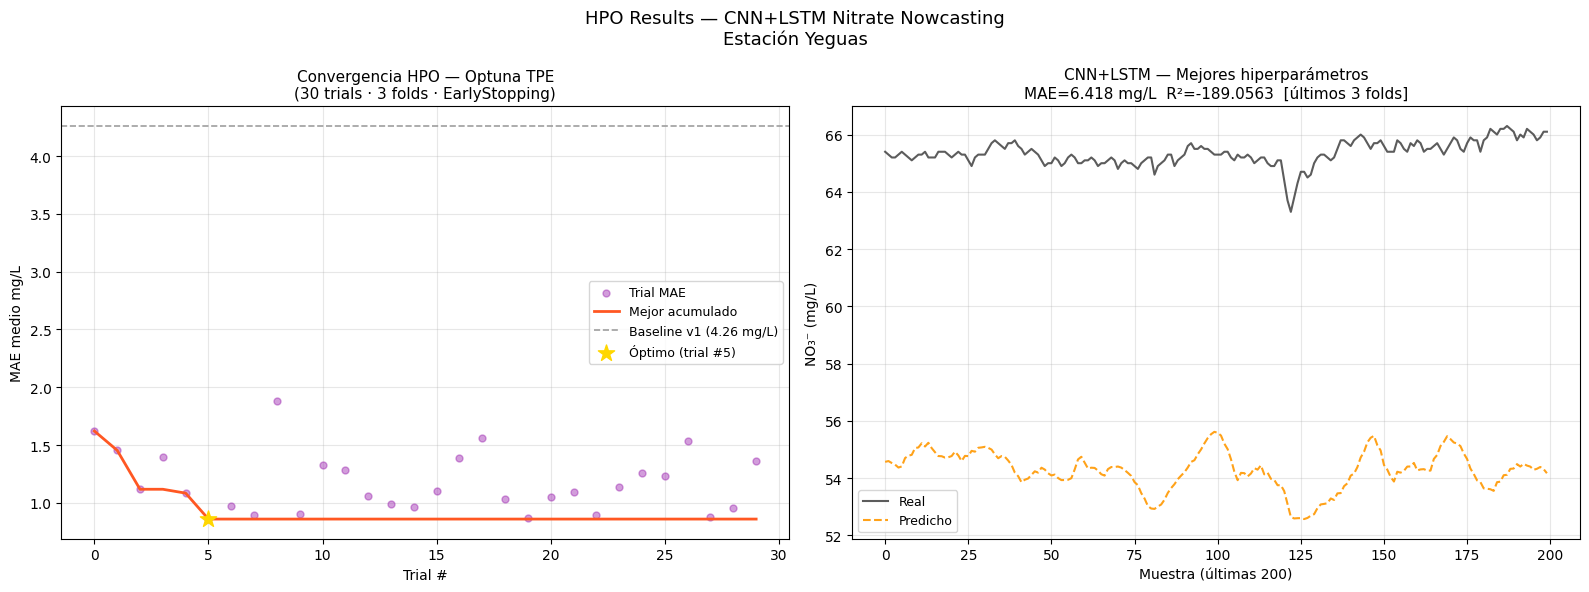

🏃 View run C_CNN_LSTM_best at: http://mlflow.example.com:5000/#/experiments/3/runs/98cb84a0f6e74d7097266629916fecb1
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
Gráfico guardado y registrado en MLflow (run: C_CNN_LSTM_best)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Izquierda: convergencia HPO (todos los trials) ─────────────────────────────
trial_nums  = [t.number for t in study.trials if t.value is not None]
trial_maes  = [t.value  for t in study.trials if t.value is not None]
best_so_far = np.minimum.accumulate(trial_maes)

axes[0].scatter(trial_nums, trial_maes, alpha=0.45, s=25,
                color='#9C27B0', zorder=2, label='Trial MAE')
axes[0].plot(trial_nums, best_so_far, color='#FF5722', linewidth=2,
             label='Mejor acumulado', zorder=3)
axes[0].axhline(4.26, color='#9E9E9E', linestyle='--',
                linewidth=1.2, label='Baseline v1 (4.26 mg/L)')
axes[0].scatter([study.best_trial.number], [study.best_value],
                color='gold', s=150, zorder=4, marker='*', label=f'Óptimo (trial #{study.best_trial.number})')
axes[0].set_xlabel('Trial #')
axes[0].set_ylabel('MAE medio mg/L')
axes[0].set_title(f'Convergencia HPO — Optuna TPE\n({N_TRIALS} trials · {HPO_FOLDS} folds · EarlyStopping)',
                  fontsize=11)
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# ── Derecha: predicciones del mejor modelo (últimas 200 muestras) ─────────────
axes[1].plot(true_C[-200:], label='Real',     color='#333', linewidth=1.5, alpha=0.8)
axes[1].plot(pred_C[-200:], label='Predicho', color='#FF9800',
             linewidth=1.5, alpha=0.9, linestyle='--')
mae_last3 = r_C['MAE'].tail(3).mean()
r2_last3  = r_C['R2'].tail(3).mean()
axes[1].set_title(f'CNN+LSTM — Mejores hiperparámetros\nMAE={mae_last3:.3f} mg/L  R²={r2_last3:.4f}  [últimos 3 folds]',
                  fontsize=11)
axes[1].set_xlabel('Muestra (últimas 200)')
axes[1].set_ylabel('NO₃⁻ (mg/L)')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.suptitle('HPO Results — CNN+LSTM Nitrate Nowcasting\nEstación Yeguas', fontsize=13)
plt.tight_layout()
_plot_path = 'outputs/hpo_results.png'
plt.savefig(_plot_path, dpi=150, bbox_inches='tight')
plt.show()

with mlflow.start_run(run_id=run_id_C):
    mlflow.log_artifact(_plot_path, artifact_path='plots')
print(f'Gráfico guardado y registrado en MLflow (run: {run_name_C})')


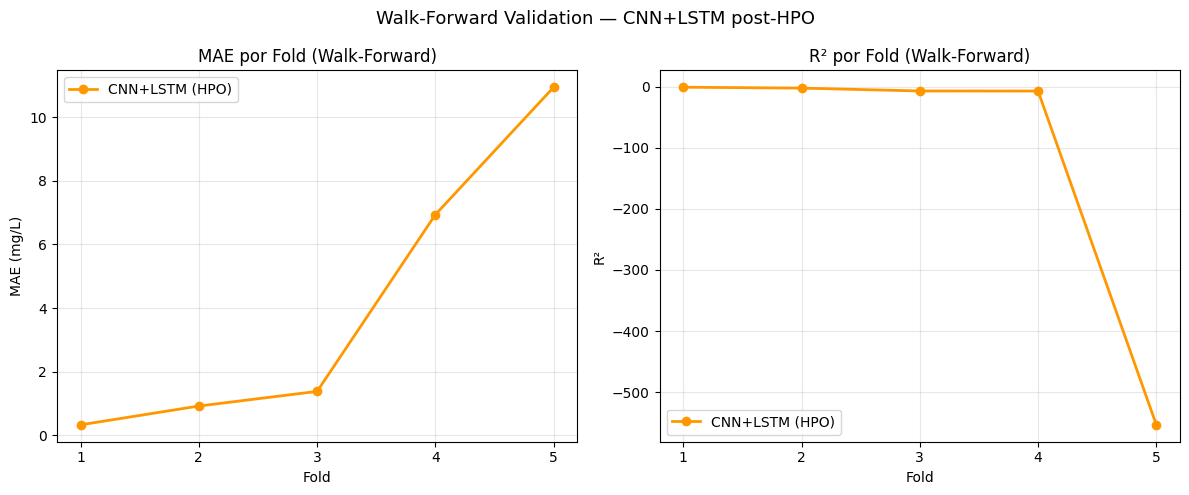

🏃 View run C_CNN_LSTM_best at: http://mlflow.example.com:5000/#/experiments/3/runs/98cb84a0f6e74d7097266629916fecb1
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
Gráfico de folds guardado y registrado en MLflow.


In [13]:
# Evolución de MAE y R² por fold — modelo campeón post-HPO
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(r_C['Fold'], r_C['MAE'], marker='o', color='#FF9800',
             linewidth=2, label='CNN+LSTM (HPO)')
axes[1].plot(r_C['Fold'], r_C['R2'],  marker='o', color='#FF9800',
             linewidth=2, label='CNN+LSTM (HPO)')

for ax, title, ylabel in [
    (axes[0], 'MAE por Fold (Walk-Forward)', 'MAE (mg/L)'),
    (axes[1], 'R² por Fold (Walk-Forward)',  'R²'),
]:
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Fold')
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xticks(range(1, N_FOLDS + 1))

plt.suptitle('Walk-Forward Validation — CNN+LSTM post-HPO', fontsize=13)
plt.tight_layout()
_folds_plot_path = 'outputs/walk_forward_folds.png'
plt.savefig(_folds_plot_path, dpi=150, bbox_inches='tight')
plt.show()

with mlflow.start_run(run_id=run_id_C):
    mlflow.log_artifact(_folds_plot_path, artifact_path='plots')
print('Gráfico de folds guardado y registrado en MLflow.')


## 9 · Integrated Gradients — Interpretabilidad del mejor modelo

> Implementado con `tf.GradientTape` nativo, sin dependencias externas.

In [14]:
def integrated_gradients(model, inputs, baseline=None, steps=50):
    """
    Calcula Integrated Gradients para un lote de inputs.
    
    Args:
        model   : modelo Keras compilado
        inputs  : np.array (batch, ...) — observaciones a explicar
        baseline: np.array misma forma que inputs — punto de referencia (0 = promedio nulo)
        steps   : número de pasos de integración (mayor → más preciso)
    Returns:
        ig : np.array misma forma que inputs — atribución de cada feature
    """
    inputs   = tf.cast(inputs,   dtype=tf.float32)
    if baseline is None:
        baseline = tf.zeros_like(inputs)
    baseline = tf.cast(baseline, dtype=tf.float32)

    # Interpolación lineal entre baseline e input
    alphas = tf.linspace(0.0, 1.0, steps + 1)[:, tf.newaxis]  # (steps+1, 1)

    # Para cada input del batch
    all_ig = []
    for idx in range(len(inputs)):
        x       = inputs[idx:idx+1]   # (1, ...)
        base    = baseline[idx:idx+1]

        # Genera path de puntos interpolados
        if x.ndim == 2:
            interp = base + alphas[:, tf.newaxis] * (x - base)   # (steps+1, 1, feat)
            interp = tf.reshape(interp, (-1, x.shape[-1]))
        else:  # 3D (window, feat)
            interp = base + alphas[:, tf.newaxis, tf.newaxis] * (x - base)  # (steps+1, 1, w, f)
            interp = tf.reshape(interp, (-1, x.shape[-2], x.shape[-1]))

        with tf.GradientTape() as tape:
            tape.watch(interp)
            preds = model(interp, training=False)

        grads    = tape.gradient(preds, interp)          # (steps+1, ...)
        avg_grad = tf.reduce_mean(grads, axis=0)         # (...)
        ig       = (x[0] - base[0]) * avg_grad          # (...)
        all_ig.append(ig.numpy())

    return np.array(all_ig)

In [15]:
# ── Cargar el modelo ganador directamente desde MLflow ────────────────────────
print(f'Cargando modelo ganador: {best_run_name}  (run_id: {best_run_id})')

best_model_uri = f"runs:/{best_run_id}/model"
best_model     = mlflow.tensorflow.load_model(best_model_uri)

# Determinar qué array de entrada usa (secuencial vs lag features)
is_seq_model = (best_run_name != "A_WideDeep")
X_all = X_seq if is_seq_model else X_lag
y_all = y_seq if is_seq_model else y_lag

print(f'Modelo cargado: {best_model.name}')
print(f'Input shape  : {best_model.input_shape}')
print(f'Datos para IG: {X_all.shape}')

Cargando modelo ganador: C_CNN_LSTM_best  (run_id: 98cb84a0f6e74d7097266629916fecb1)


Modelo cargado: C_CNN_LSTM_HPO
Input shape  : (None, 24, 12)
Datos para IG: (3096, 24, 12)


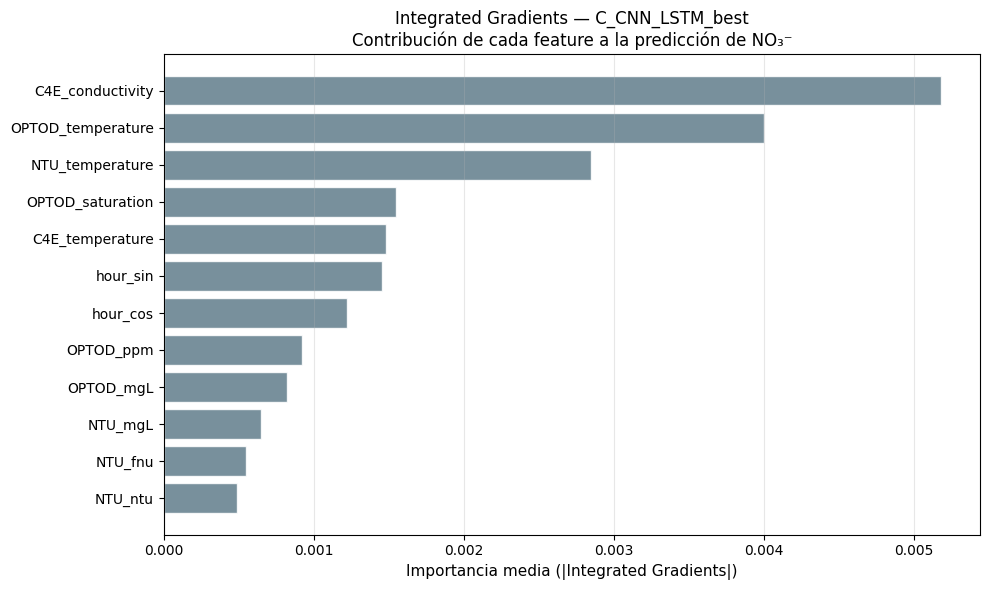

🏃 View run C_CNN_LSTM_best at: http://mlflow.example.com:5000/#/experiments/3/runs/98cb84a0f6e74d7097266629916fecb1
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3
── Top 5 features más influyentes ──
  1. C4E_conductivity                     IG=0.00518
  2. OPTOD_temperature                    IG=0.00400
  3. NTU_temperature                      IG=0.00285
  4. OPTOD_saturation                     IG=0.00155
  5. C4E_temperature                      IG=0.00148

Integrated Gradients registrados en MLflow run: 98cb84a0f6e74d7097266629916fecb1


In [16]:
# ── Calcular IG sobre 50 muestras aleatorias ──────────────────────────────────
np.random.seed(42)
sample_idx = np.random.choice(len(X_all), size=50, replace=False)
X_sample   = X_all[sample_idx].astype(np.float32)

ig_values  = integrated_gradients(best_model, X_sample, steps=50)

# Colapsar dimensión temporal si el modelo es secuencial
if ig_values.ndim == 3:
    ig_flat = np.abs(ig_values).mean(axis=1)  # media sobre pasos de tiempo → (50, n_features)
else:
    ig_flat = np.abs(ig_values)[:, :len(FEATURE_COLS)]

mean_ig = ig_flat.mean(axis=0)[:len(FEATURE_COLS)]  # media sobre muestras

# ── Gráfico de importancia ─────────────────────────────────────────────────────
sorted_idx   = np.argsort(mean_ig)[::-1]
top_features = [FEATURE_COLS[i] for i in sorted_idx]
top_values   = mean_ig[sorted_idx]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_features[::-1], top_values[::-1],
        color=COLORS.get(best_run_name, '#607D8B'), edgecolor='white', alpha=0.85)
ax.set_xlabel('Importancia media (|Integrated Gradients|)', fontsize=11)
ax.set_title(f'Integrated Gradients — {best_run_name}\n'
             'Contribución de cada feature a la predicción de NO₃⁻', fontsize=12)
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
_ig_plot_path = 'outputs/integrated_gradients.png'
plt.savefig(_ig_plot_path, dpi=150, bbox_inches='tight')
plt.show()

# ── Registrar importancias y gráfico en MLflow ────────────────────────────────
ig_dict = {f"ig_{feat}": float(val) for feat, val in zip(FEATURE_COLS, mean_ig)}
with mlflow.start_run(run_id=best_run_id):
    mlflow.log_metrics(ig_dict)
    mlflow.log_artifact(_ig_plot_path, artifact_path="interpretability")

print('── Top 5 features más influyentes ──')
for i in range(5):
    print(f'  {i+1}. {top_features[i]:<35s}  IG={top_values[i]:.5f}')
print(f'\nIntegrated Gradients registrados en MLflow run: {best_run_id}')


## 10 · Registro en MLflow Model Registry y exportación de artefactos

In [17]:
# ── Registrar el modelo ganador en el MLflow Model Registry ───────────────────
REGISTRY_NAME = "nitrate_nowcasting_best_01"

model_uri       = f"runs:/{best_run_id}/model"
registered_mv   = mlflow.register_model(model_uri, REGISTRY_NAME)

print(f'Modelo registrado en Model Registry:')
print(f'  Nombre  : {registered_mv.name}')
print(f'  Versión : {registered_mv.version}')
print(f'  Run ID  : {best_run_id}')

# ── Guardar escaladores y metadatos como artefactos del run ganador ────────────
os.makedirs('outputs/artifacts', exist_ok=True)

joblib.dump(X_scaler, 'outputs/artifacts/X_scaler.pkl')
joblib.dump(y_scaler, 'outputs/artifacts/y_scaler.pkl')

best_metrics = runs_df.iloc[0]
meta = {
    'model_name':      REGISTRY_NAME,
    'model_version':   registered_mv.version,
    'run_name':        best_run_name,
    'run_id':          best_run_id,
    'window':          WINDOW,
    'lag_steps':       LAG_STEPS,
    'features':        FEATURE_COLS,
    'mae_last3_folds': float(best_metrics['metrics.last3_mae']),
    'r2_last3_folds':  float(best_metrics['metrics.last3_r2']),
    'created':         pd.Timestamp.now().isoformat(),
}
with open('outputs/artifacts/meta.json', 'w') as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

with mlflow.start_run(run_id=best_run_id):
    mlflow.log_artifact('outputs/artifacts/X_scaler.pkl', artifact_path='scalers')
    mlflow.log_artifact('outputs/artifacts/y_scaler.pkl', artifact_path='scalers')
    mlflow.log_artifact('outputs/artifacts/meta.json',    artifact_path='metadata')

print('\n── Artefactos registrados en MLflow ──')
print('  scalers/X_scaler.pkl')
print('  scalers/y_scaler.pkl')
print('  metadata/meta.json')
print()
print('── Metadatos ──')
print(json.dumps(meta, indent=2, ensure_ascii=False))
print()
print('Para cargar el modelo en producción:')
print(f'  model = mlflow.tensorflow.load_model("models:/{REGISTRY_NAME}/latest")')
print('  # o por versión específica:')
print(f'  model = mlflow.tensorflow.load_model("models:/{REGISTRY_NAME}/{registered_mv.version}")')


Registered model 'nitrate_nowcasting_best_01' already exists. Creating a new version of this model...
2026/03/09 10:08:56 WARNING mlflow.tracking._model_registry.fluent: Run with id 98cb84a0f6e74d7097266629916fecb1 has no artifacts at artifact path 'model', registering model based on models:/m-a9fc5af79d094dcfaa7b0f1f64936b2b instead
2026/03/09 10:08:56 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: nitrate_nowcasting_best_01, version 2


Modelo registrado en Model Registry:
  Nombre  : nitrate_nowcasting_best_01
  Versión : 2
  Run ID  : 98cb84a0f6e74d7097266629916fecb1
🏃 View run C_CNN_LSTM_best at: http://mlflow.example.com:5000/#/experiments/3/runs/98cb84a0f6e74d7097266629916fecb1
🧪 View experiment at: http://mlflow.example.com:5000/#/experiments/3

── Artefactos registrados en MLflow ──
  scalers/X_scaler.pkl
  scalers/y_scaler.pkl
  metadata/meta.json

── Metadatos ──
{
  "model_name": "nitrate_nowcasting_best_01",
  "model_version": "2",
  "run_name": "C_CNN_LSTM_best",
  "run_id": "98cb84a0f6e74d7097266629916fecb1",
  "window": 24,
  "lag_steps": [
    1,
    2,
    4
  ],
  "features": [
    "C4E_conductivity",
    "C4E_temperature",
    "NTU_fnu",
    "NTU_mgL",
    "NTU_ntu",
    "NTU_temperature",
    "OPTOD_mgL",
    "OPTOD_ppm",
    "OPTOD_saturation",
    "OPTOD_temperature",
    "hour_sin",
    "hour_cos"
  ],
  "mae_last3_folds": 6.417619148890178,
  "r2_last3_folds": -189.05633640289307,
  "created": "

Created version '2' of model 'nitrate_nowcasting_best_01'.


## 11 · Guía de uso MLflow

### Visualizar experimentos
```bash
# En la terminal, desde la raíz del proyecto:
mlflow ui --port 5000
# → http://127.0.0.1:5000
```

### Comparar runs programáticamente
```python
import mlflow

runs = mlflow.search_runs(
    experiment_names=["nitrate_nowcasting"],
    order_by=["metrics.last3_mae ASC"]
)
print(runs[['tags.mlflow.runName','metrics.last3_mae','metrics.last3_r2']].to_string())
```

### Cargar modelo ganador para inferencia
```python
import mlflow.tensorflow, joblib, numpy as np

# Desde Model Registry (siempre apunta a la mejor versión)
model     = mlflow.tensorflow.load_model("models:/nitrate_nowcasting_best_01/latest")
X_scaler  = joblib.load("outputs/artifacts/X_scaler.pkl")
y_scaler  = joblib.load("outputs/artifacts/y_scaler.pkl")

# Inferencia (requiere ventana de 96 pasos × n_features)
X_new     = X_scaler.transform(raw_sensor_data)          # (96, n_features)
X_input   = X_new[np.newaxis, ...]                        # (1, 96, n_features)
pred_norm = model.predict(X_input).flatten()
pred_mgL  = y_scaler.inverse_transform(pred_norm.reshape(-1, 1)).flatten()
print(f"NO₃⁻ estimado: {pred_mgL[0]:.2f} mg/L")
```

### Estructura del proyecto
```
NITRATE_model/
├── data/
│   ├── raw/          ← CSV originales del sensor
│   └── processed/    ← YEGUAS_data.csv (limpio)
├── outputs/
│   ├── artifacts/    ← escaladores (.pkl) y meta.json
│   ├── model_comparison.png
│   ├── walk_forward_folds.png
│   └── integrated_gradients.png
├── src/
│   ├── csv_cleaner.py
│   ├── main.py
│   └── model_trainning.py
├── tf_experiments.ipynb
├── model_selection.md
├── pyproject.toml
└── README.md
```

### Flujo completo MLflow
```
tf_experiments.ipynb
  ├── Setup + MLflow Experiment config
  ├── Run A/B/C/D  → mlflow.start_run() por cada arquitectura
  │     ├── mlflow.log_params()          # hiperparámetros
  │     ├── mlflow.log_metrics(step=k)   # MAE/RMSE/R² por fold
  │     ├── mlflow.log_metrics()         # resumen mean/last3
  │     └── mlflow.tensorflow.log_model()# modelo final .tf
  ├── Comparativa  → mlflow.search_runs() ordena por last3_mae
  ├── Gráficos     → mlflow.log_artifact() en run ganador
  ├── Integrated Gradients → mlflow.log_metrics(ig_<feature>)
  └── Model Registry → mlflow.register_model() "nitrate_nowcasting_best_01"
```
